In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## hyperparameter-grid

**Figure 3: Validation accuracy over learning rate and batch size.** The outlined cell marks the best setting. Learning rate 1e-4 with batch size 32 reaches the highest accuracy, 0.768, while the largest learning rate, 3e-4, drops to 0.688–0.722.

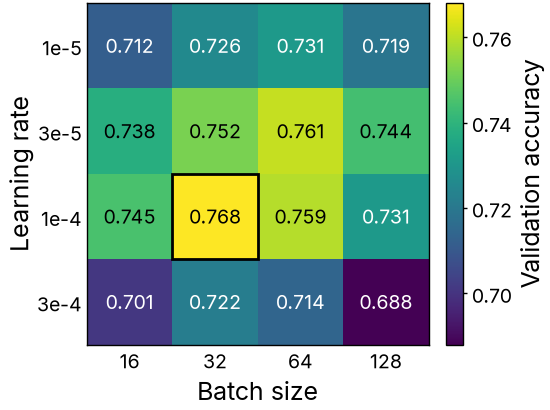

In [2]:
with open("../data/hyperparameter-grid.json") as f:
    data = json.load(f)
accuracy = np.array(data["accuracy"])

fig, ax = plt.subplots(figsize=(2.75, 2.5), layout="constrained")
im = ax.imshow(accuracy, aspect="auto")
for i, row in enumerate(accuracy):
    for j, v in enumerate(row):
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", color=text_color(im.cmap(im.norm(v))))
best_i, best_j = np.unravel_index(accuracy.argmax(), accuracy.shape)
ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=1))
ax.set_xticks(range(len(data["batch_sizes"])), labels=data["batch_sizes"])
ax.set_yticks(range(len(data["learning_rates"])), labels=data["learning_rates"])
ax.tick_params(length=0)
ax.grid(False)
ax.set_xlabel("Batch size")
ax.set_ylabel("Learning rate")
fig.colorbar(im, ax=ax, label="Validation accuracy")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/hyperparameter-grid.pdf")
fig.savefig("../outputs/hyperparameter-grid.png")
plt.show()